In [24]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 6. Analysis
This notebook...

In [25]:
weight_df = pd.read_csv('../data/weight_files/all_weights.csv')
weight_df.shape # 403 + 46 = 449 edges

(449, 9)

In [26]:
weight_df.head()

,source_ID,target_ID,GT_weight,LG_weight,TRF_weight,relik_weight,relik_cie_weight,spotlight_weight,direction
0,Q9068,Q517,1,1,1,0,3,1,in
1,Q360481,Q517,13,6,7,6,13,7,in
2,Q162296,Q517,2,2,2,2,5,2,in
3,Q354477,Q517,0,0,0,0,0,2,in
4,Q68771,Q517,0,0,0,0,16,3,in


## Compare ground truth to predictions

In [27]:
models = [
    ('spotlight_weight', 'Spotlight'),
    ('LG_weight', 'lg'),
    ('TRF_weight', 'trf'),
    ('relik_weight', 'Relik'),
    ('relik_cie_weight', 'Relik_cie')
]

### Raw values

In [28]:
for (col, label) in models:
    err = weight_df[col] - weight_df['GT_weight']

    print(f'MAE for {label} {err.abs().mean():.1f}')


MAE for Spotlight 0.4
MAE for lg 5.2
MAE for trf 5.4
MAE for Relik 0.6
MAE for Relik_cie 1.7


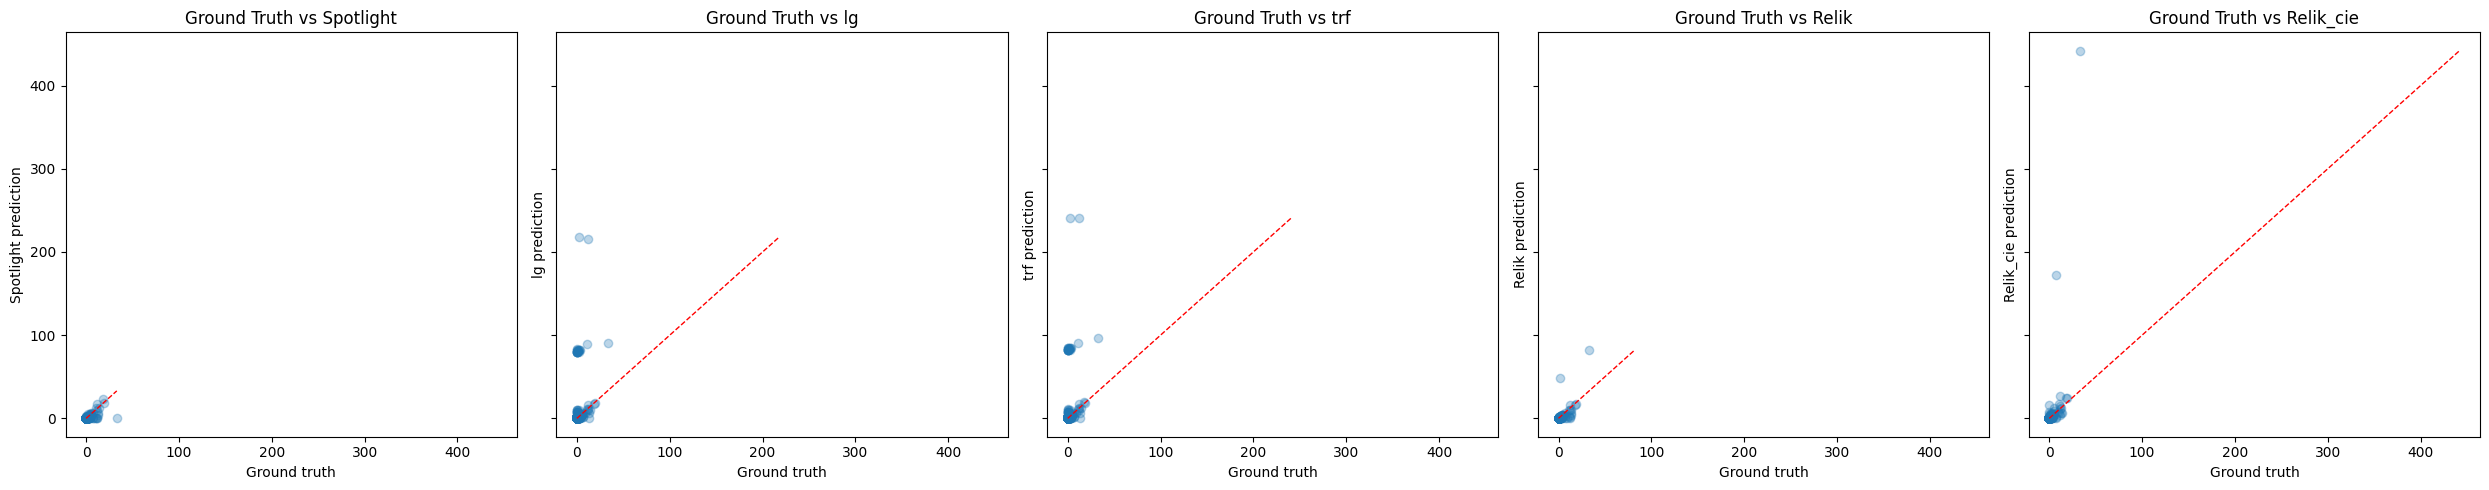

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharex=True, sharey=True)

for ax, (col, label) in zip(axes, models):
    ax.scatter(weight_df['GT_weight'], weight_df[col], alpha=0.3)

    lims = [
        min(weight_df['GT_weight'].min(), weight_df[col].min()),
        max(weight_df['GT_weight'].max(), weight_df[col].max())
    ]
    ax.plot(lims, lims, 'r--', linewidth=1)

    ax.set_xlabel('Ground truth')
    ax.set_ylabel(f'{label} prediction')
    ax.set_title(f'Ground Truth vs {label}')

plt.tight_layout()
plt.show()

### Log values

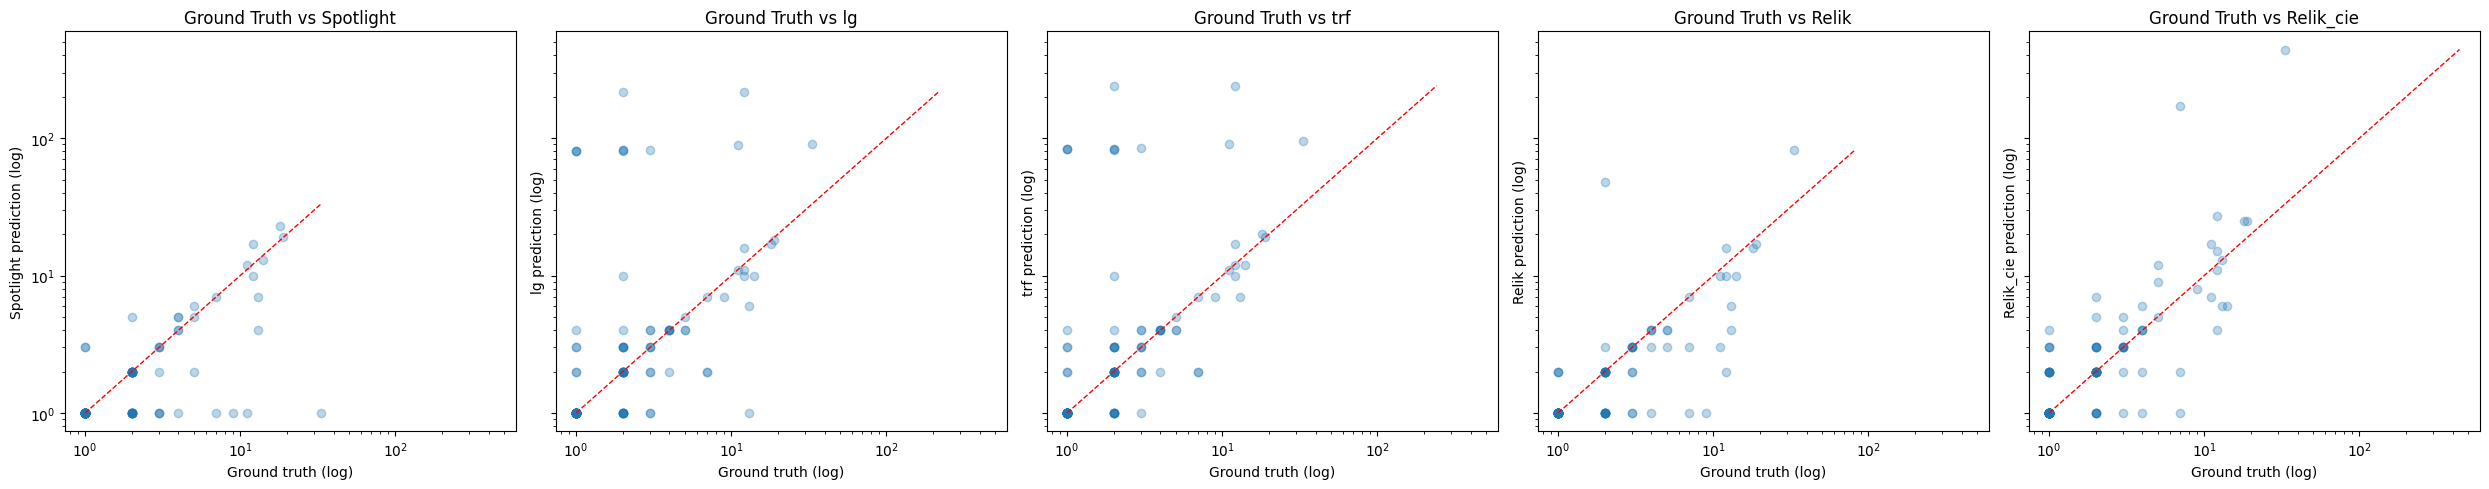

In [30]:
fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharex=True, sharey=True)

for ax, (col, label) in zip(axes, models):
    # keep only rows where both values are > 0 (log can't show 0)
    data = weight_df[(weight_df['GT_weight'] > 0) & (weight_df[col] > 0)]

    ax.scatter(data['GT_weight'], data[col], alpha=0.3)

    lims = [
        min(data['GT_weight'].min(), data[col].min()),
        max(data['GT_weight'].max(), data[col].max())
    ]
    ax.plot(lims, lims, 'r--', linewidth=1)

    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlabel('Ground truth (log)')
    ax.set_ylabel(f'{label} prediction (log)')
    ax.set_title(f'Ground Truth vs {label}')

plt.tight_layout()
plt.show()

In [31]:
print('Spearman Correlation:')

for (col, label) in models:
    spearman_corr = weight_df['GT_weight'].corr(weight_df[col], method='spearman')
    print(f"\t{label}:", round(spearman_corr, 3))


print('\nPearson Correlation:')

for col, label in models:
    pearson_corr = weight_df['GT_weight'].corr(weight_df[col], method='pearson')
    print(f"\t{label}:", round(pearson_corr, 3))

print('\nLog Pearson Correlation:')

for col, label in models:
    r_log = np.log1p(weight_df['GT_weight']).corr(np.log1p(weight_df[col]), method='pearson')
    print(f"\t{label}:", round(r_log, 3))

Spearman Correlation:
	Spotlight: 0.826
	lg: 0.535
	trf: 0.536
	Relik: 0.832
	Relik_cie: 0.889

Pearson Correlation:
	Spotlight: 0.681
	lg: 0.279
	trf: 0.284
	Relik: 0.71
	Relik_cie: 0.632

Log Pearson Correlation:
	Spotlight: 0.789
	lg: 0.465
	trf: 0.465
	Relik: 0.831
	Relik_cie: 0.857


In [32]:
results = []
for col, label in models:
    data = weight_df[(weight_df['GT_weight'] > 0) & (weight_df[col] > 0)]

    log_gt   = np.log10(data['GT_weight'])
    log_pred = np.log10(data[col])

    err  = log_pred - log_gt
    mse  = np.mean(err ** 2)
    rmse = np.sqrt(mse)

    results.append({'model': label, 'n': len(data),
                    'log_MSE': mse, 'log_RMSE': rmse})

pd.DataFrame(results)

,model,n,log_MSE,log_RMSE
0,Spotlight,105,0.078692,0.280521
1,lg,114,0.286144,0.534924
2,trf,114,0.277399,0.526687
3,Relik,98,0.074923,0.273721
4,Relik_cie,118,0.074455,0.272865


In [33]:
out_weight_df = weight_df[weight_df['direction']=='out']

# only napoleons outgoing edges
results = []
for col, label in models:
    data = out_weight_df[(out_weight_df['GT_weight'] > 0) & (out_weight_df[col] > 0)]

    log_gt   = np.log10(data['GT_weight'])
    log_pred = np.log10(data[col])

    err  = log_pred - log_gt
    mse  = np.mean(err ** 2)
    rmse = np.sqrt(mse)

    results.append({'model': label, 'n': len(data),
                    'log_MSE': mse, 'log_RMSE': rmse})

pd.DataFrame(results)

,model,n,log_MSE,log_RMSE
0,Spotlight,63,0.082239,0.286773
1,lg,77,0.414180,0.643568
2,trf,75,0.412027,0.641893
3,Relik,61,0.108476,0.329357
4,Relik_cie,76,0.071262,0.266949


In [34]:
weight_df[weight_df['source_ID']=='Q7721']

,source_ID,target_ID,GT_weight,LG_weight,TRF_weight,relik_weight,relik_cie_weight,spotlight_weight,direction
45,Q7721,Q517,33,90,96,82,442,1,in


In [35]:
weight_df[weight_df['relik_cie_weight']>15]

,source_ID,target_ID,GT_weight,LG_weight,TRF_weight,relik_weight,relik_cie_weight,spotlight_weight,direction
4,Q68771,Q517,0,0,0,0,16,3,in
20,Q708011,Q517,18,17,20,16,25,23,in
29,Q53444,Q517,19,18,19,17,25,19,in
31,Q356933,Q517,11,11,11,10,17,12,in
40,Q5547,Q517,12,16,17,16,27,17,in
45,Q7721,Q517,33,90,96,82,442,1,in
127,Q517,Q131691,7,2,2,3,172,0,out


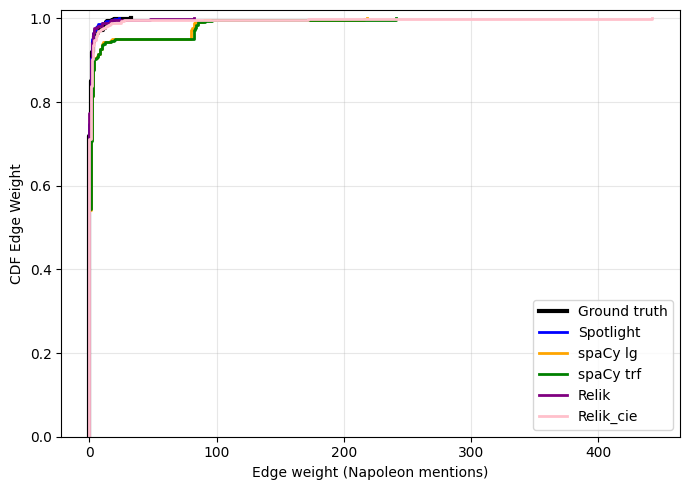

In [36]:
cols = [
    ('GT_weight',        'Ground truth', 'black'),
    ('spotlight_weight', 'Spotlight',    'blue'),
    ('LG_weight',        'spaCy lg',     'orange'),
    ('TRF_weight',       'spaCy trf',    'green'),
    ('relik_weight',     'Relik',        'purple'),
    ('relik_cie_weight', 'Relik_cie',    'pink')

]

fig, ax = plt.subplots(figsize=(7, 5))

for col, label, color in cols:
    x = np.sort(weight_df[col])
    y = np.arange(1, len(x) + 1) / len(x)
    ax.step(x, y, where='post', label=label, color=color,
            linewidth=3 if col == 'GT_weight' else 2)

ax.set_xlabel('Edge weight (Napoleon mentions)')
ax.set_ylabel('CDF Edge Weight')
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()